# Volatilidad incierta: cuánto vale un bull call spread
UPC Quant Society · basado en Avellaneda, Levy y Parás (1995), *Pricing and Hedging Derivative Securities in Markets with Uncertain Volatilities*

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [22]:
# Parámetros del paper
S0 = 95.0          # precio de la acción HOY
K_compra = 90.0    # call comprada
K_venta = 100.0    # call vendida
T = 0.5            # años hasta el vencimiento
r = 0.05           # tipo de interés continuo (sin dividendos)

sigma_bs = 0.25    # volatilidad conocida (bloque 2)
sigma_min = 0.10   # rango de volatilidad incierta (bloques 3 y 4)
sigma_max = 0.40

## 1. ¿Por qué alguien compraría este spread?
El cliente espera una subida moderada: compra la call 90 y vende la call 100 para abaratarla, a cambio de renunciar a lo que suba por encima de 100.

In [23]:
def cobro_spread(S_final):
    return np.maximum(S_final - K_compra, 0) - np.maximum(S_final - K_venta, 0)

for S_final in [85, 95, 105]:
    print(f"Termina en {S_final}: cobra {cobro_spread(S_final):.0f}")

Termina en 85: cobra 0
Termina en 95: cobra 5
Termina en 105: cobra 10


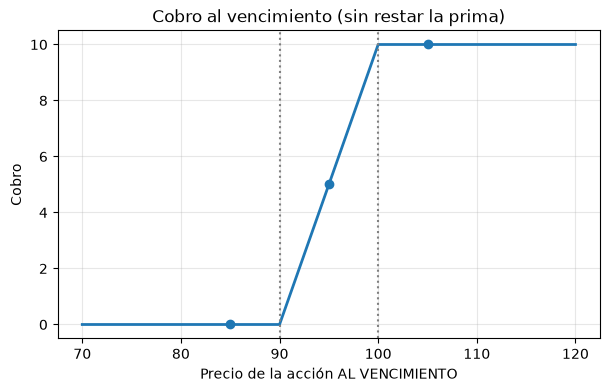

In [24]:
S_final = np.linspace(70, 120, 501)

plt.figure(figsize=(7, 4))
plt.plot(S_final, cobro_spread(S_final), lw=2)
plt.scatter([85, 95, 105], cobro_spread(np.array([85, 95, 105])), zorder=3)
plt.axvline(K_compra, ls=":", c="grey")
plt.axvline(K_venta, ls=":", c="grey")
plt.title("Cobro al vencimiento (sin restar la prima)")
plt.xlabel("Precio de la acción AL VENCIMIENTO")
plt.ylabel("Cobro")
plt.grid(alpha=0.3)
plt.show()

## 2. ¿Cuánto vale hoy si conocemos la volatilidad?

In [25]:
def call_bs(S, K, sigma, tau=T):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    d2 = d1 - sigma * np.sqrt(tau)
    return S * norm.cdf(d1) - K * np.exp(-r * tau) * norm.cdf(d2)

def spread_bs(S, sigma):
    return call_bs(S, K_compra, sigma) - call_bs(S, K_venta, sigma)

In [26]:
precio_hoy = spread_bs(S0, sigma_bs)

print(f"Call 90 HOY:  {call_bs(S0, K_compra, sigma_bs):.2f}")
print(f"Call 100 HOY: {call_bs(S0, K_venta, sigma_bs):.2f}")
print(f"Spread HOY (S={S0:.0f}, quedan {T*12:.0f} meses): {precio_hoy:.2f}")
print(f"Cobro si TERMINA en {S0:.0f}:              {cobro_spread(S0):.2f}")
print(f"Cobro si termina en 100:            {cobro_spread(100):.2f}")

print(f"Si termina en 105 cobrare los 10 menos lo que he pagado hoy")
print(f"Beneficio neto si termina en 105:     {cobro_spread(105) - precio_hoy:.2f}")

Call 90 HOY:  10.68
Call 100 HOY: 5.59
Spread HOY (S=95, quedan 6 meses): 5.09
Cobro si TERMINA en 95:              5.00
Cobro si termina en 100:            10.00
Si termina en 105 cobrare los 10 menos lo que he pagado hoy
Beneficio neto si termina en 105:     4.91


## 3. ¿Qué cambia si solo sabemos que la volatilidad estará entre el 10 % y el 40 %?
### 3a. Volatilidad desconocida pero constante

In [27]:
S_hoy = np.linspace(60, 130, 281)          # precio de la acción HOY
sigmas = np.linspace(sigma_min, sigma_max, 61)

# una fila por sigma: el spread completo, ambas calls con la misma sigma
precios = np.array([spread_bs(S_hoy, s) for s in sigmas])
bs_min = precios.min(axis=0)
bs_max = precios.max(axis=0)

for S in [85, 90, 95, 105]:
    i = np.argmin(abs(S_hoy - S))
    print(f"S HOY={S}: {bs_min[i]:.2f} (sigma={sigmas[precios[:, i].argmin()]:.0%})"
          f" – {bs_max[i]:.2f} (sigma={sigmas[precios[:, i].argmax()]:.0%})")

S HOY=85: 1.23 (sigma=10%) – 3.21 (sigma=40%)
S HOY=90: 3.35 (sigma=10%) – 3.96 (sigma=34%)
S HOY=95: 4.68 (sigma=40%) – 6.01 (sigma=10%)
S HOY=105: 6.03 (sigma=40%) – 9.22 (sigma=10%)


### 3b. Volatilidad que puede cambiar con el tiempo y con el spot (BSB)
En cada nodo, ¿qué sigma elegiría el peor escenario para quien vende?

In [28]:
def continuacion(V, sigma, dt, dx):
    # media descontada de los tres hijos (arriba, medio, abajo) en log-precio
    mu = r - 0.5 * sigma**2
    p_up = 0.5 * sigma**2 * dt / dx**2 + 0.5 * mu * dt / dx
    p_dn = 0.5 * sigma**2 * dt / dx**2 - 0.5 * mu * dt / dx
    return np.exp(-r * dt) * (p_up * V[2:] + (1 - p_up - p_dn) * V[1:-1] + p_dn * V[:-2])

def cota_bsb(cota, n_pasos=400):
    dt = T / n_pasos
    dx = sigma_max * np.sqrt(dt)              # paso del árbol trinomial del paper
    extra = int(np.ceil(0.5 / dx))            # nodos de más para cubrir spots HOY lejos de S0
    j = np.arange(-(n_pasos + extra), n_pasos + extra + 1)
    S = S0 * np.exp(j * dx)                   # precios AL VENCIMIENTO
    V = cobro_spread(S)
    elegir = np.maximum if cota == "superior" else np.minimum
    for _ in range(n_pasos):
        # decisión local: de las dos continuaciones admisibles, la mayor (o la menor)
        V = elegir(continuacion(V, sigma_min, dt, dx), continuacion(V, sigma_max, dt, dx))
        S = S[1:-1]                           # cada paso atrás perdemos un nodo por lado
    return S, V                               # S ya es el precio HOY

In [29]:
S_arbol, bsb_inf = cota_bsb("inferior")
_, bsb_sup = cota_bsb("superior")
print(f"BSB en S HOY={S0:.0f}: {np.interp(S0, S_arbol, bsb_inf):.2f} – {np.interp(S0, S_arbol, bsb_sup):.2f}")

# ¿depende del número de pasos?
for n in [100, 400, 1600]:
    Sa, inf_n = cota_bsb("inferior", n)
    _, sup_n = cota_bsb("superior", n)
    print(f"n={n:4d}: {np.interp(S0, Sa, inf_n):.3f} – {np.interp(S0, Sa, sup_n):.3f}")

BSB en S HOY=95: 2.83 – 7.43
n= 100: 2.794 – 7.415
n= 400: 2.830 – 7.431
n=1600: 2.836 – 7.442


## 4. ¿Qué nos dice la figura 3?

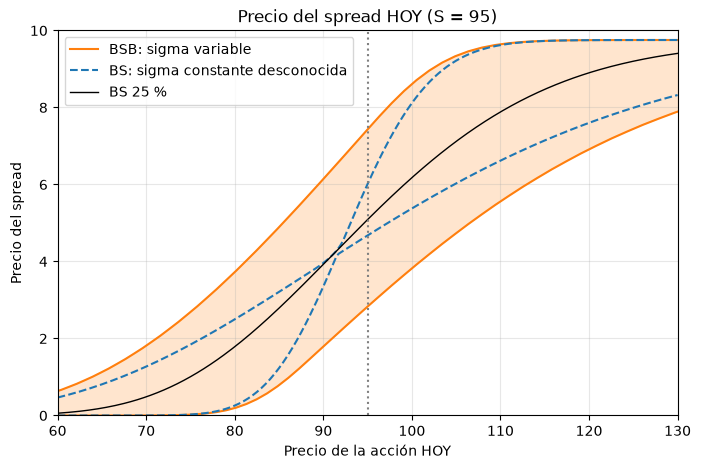

BS 25 %:             5.09
BS sigma constante:  4.68 – 6.01
BSB sigma variable:  2.83 – 7.43


In [30]:
def figura(S):
    plt.figure(figsize=(8, 5))
    plt.fill_between(S_arbol, bsb_inf, bsb_sup, color="tab:orange", alpha=0.2)
    plt.plot(S_arbol, bsb_sup, c="tab:orange", label="BSB: sigma variable")
    plt.plot(S_arbol, bsb_inf, c="tab:orange")
    plt.plot(S_hoy, bs_max, "--", c="tab:blue", label="BS: sigma constante desconocida")
    plt.plot(S_hoy, bs_min, "--", c="tab:blue")
    plt.plot(S_hoy, spread_bs(S_hoy, sigma_bs), c="k", lw=1, label="BS 25 %")
    plt.axvline(S, ls=":", c="grey")
    plt.xlim(60, 130)
    plt.ylim(0, 10)
    plt.title(f"Precio del spread HOY (S = {S:.0f})")
    plt.xlabel("Precio de la acción HOY")
    plt.ylabel("Precio del spread")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    print(f"BS 25 %:             {spread_bs(S, sigma_bs):.2f}")
    print(f"BS sigma constante:  {np.interp(S, S_hoy, bs_min):.2f} – {np.interp(S, S_hoy, bs_max):.2f}")
    print(f"BSB sigma variable:  {np.interp(S, S_arbol, bsb_inf):.2f} – {np.interp(S, S_arbol, bsb_sup):.2f}")

figura(S0)
# paper en S=95: BS 25 % ≈ 5,09 · BS constante ≈ 4,68–6,01 · BSB ≈ 2,83–7,44 (tabla 1)

Fijaos que la curva de BS con sigma constante desconocida, para cada spot, prueba todas las sigmas entre el 10 % y el 40 % y se queda con el spread máximo y el mínimo.

¿Por qué parece que se cruzan?
Lo que se cruzan son la curva del 10 % y la del 40 %. Con el spot bajo, una sigma alta me ayuda porque necesito que la acción suba, así que el 40 % da el máximo. Con el spot alto, la sigma alta me perjudica porque ya casi cobro 10 y solo puedo perder, así que el 40 % pasa a dar el mínimo. Las líneas azules cambian de curva en ese punto.

¿Por qué una crece de golpe?
Es la del 10 %. Con poca volatilidad el futuro está casi decidido, así que el precio de hoy se parece al payoff, que salta de 0 a 10 entre 90 y 100. La del 40 % suaviza ese salto y queda casi recta.

In [31]:
# comprobación: la banda constante cae dentro de la BSB
inf_en_S = np.interp(S_hoy, S_arbol, bsb_inf)
sup_en_S = np.interp(S_hoy, S_arbol, bsb_sup)
print("¿BS constante dentro de BSB?", np.all(bs_min >= inf_en_S - 1e-2) and np.all(bs_max <= sup_en_S + 1e-2))

¿BS constante dentro de BSB? True


## 5. Tu turno
**a)** Movemos el spot a 85 y luego a 105. ¿En qué caso nos acercamos al cobro máximo de 10?

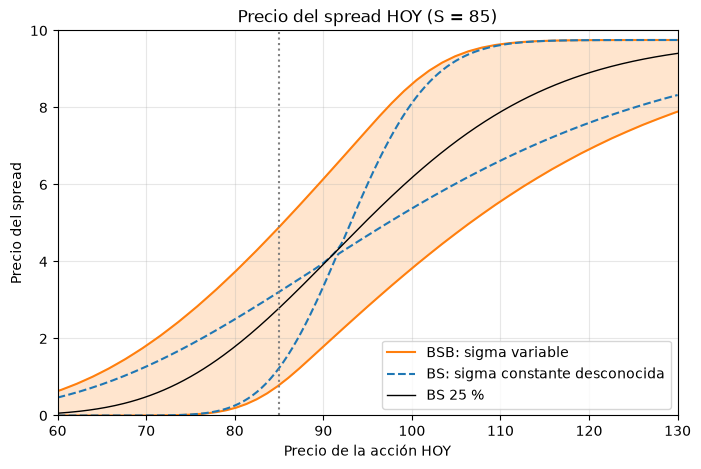

BS 25 %:             2.79
BS sigma constante:  1.23 – 3.21
BSB sigma variable:  0.79 – 4.89


In [32]:
figura(85)

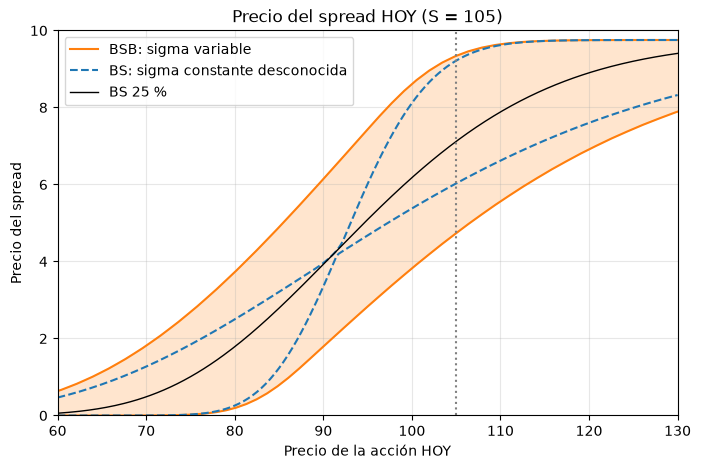

BS 25 %:             7.12
BS sigma constante:  6.03 – 9.22
BSB sigma variable:  4.74 – 9.34


In [33]:
figura(105)

**b)** Fijamos sigma_min = sigma_max = 25 %. ¿Qué debería pasar con las dos bandas?

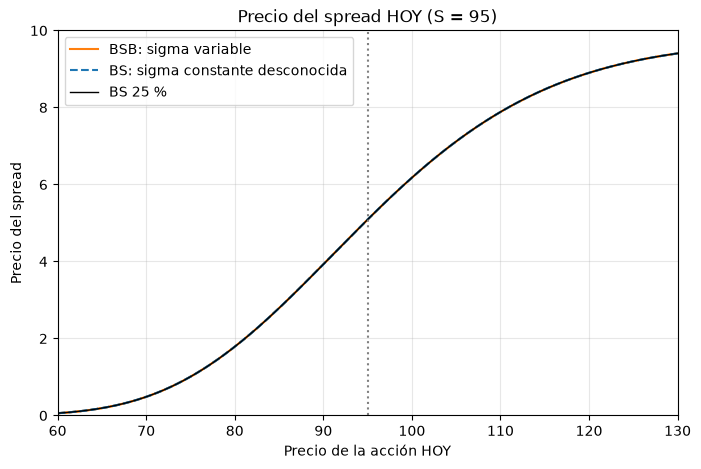

BS 25 %:             5.09
BS sigma constante:  5.09 – 5.09
BSB sigma variable:  5.09 – 5.09
Distancia máx. de BSB a BS 25 %: 0.0019


In [34]:
sigma_min = sigma_max = 0.25

precios = np.array([spread_bs(S_hoy, s) for s in np.linspace(sigma_min, sigma_max, 61)])
bs_min, bs_max = precios.min(axis=0), precios.max(axis=0)
S_arbol, bsb_inf = cota_bsb("inferior")
_, bsb_sup = cota_bsb("superior")

figura(S0)
print(f"Distancia máx. de BSB a BS 25 %: {np.max(abs(bsb_sup - spread_bs(S_arbol, 0.25))):.4f}")

## Para llevarse
El cliente compra el spread para expresar una visión alcista moderada pagando menos que por la call 90 sola. La mesa que se lo vende mira la cota superior BSB: es el capital que necesita hoy para cubrir el pago sea cual sea la volatilidad dentro del rango.